<a href="https://colab.research.google.com/github/Ch3ddarr/dsb_capstone/blob/main/capstone2/02_Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelling for CTU-13 Botnet Detection - EDA (Scenario 1)

This notebook is dedicated to modelling for my second capstone idea, botnet detection. I will be going through my cleaned dataset and perform additional cleansing, filtering etc. in order to get the answer to the question **Can machine learning help us identify malicious botnet traffic?**

In [25]:
import pandas as pd

In [26]:
# Reading the data
df = pd.read_csv('/content/ml_dataset.csv')

In [27]:
#
df.head()

,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label,traffic_type,target
0,2011/08/10 09:46:53.160043,0.000000,udp,147.32.80.9,53,->,147.32.86.111,54230,INT,0.0,NaN,1,141,141,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
1,2011/08/10 09:46:54.045343,0.000000,udp,147.32.80.9,53,->,147.32.86.111,58314,INT,0.0,NaN,1,247,247,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
2,2011/08/10 09:46:54.460552,0.000000,udp,147.32.80.9,53,->,147.32.86.111,54823,INT,0.0,NaN,1,173,173,flow=From-Normal-V42-UDP-CVUT-DNS-Server,From-Normal,0
3,2011/08/10 09:46:54.779125,0.000291,udp,147.32.84.134,40693,<->,147.32.80.9,53,CON,0.0,0.0,2,207,72,flow=From-Normal-V42-Jist,From-Normal,0
4,2011/08/10 09:46:54.779641,0.000321,udp,147.32.84.134,47415,<->,147.32.80.9,53,CON,0.0,0.0,2,247,72,flow=From-Normal-V42-Jist,From-Normal,0


In [28]:
# Looking at the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71219 entries, 0 to 71218
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   StartTime     71219 non-null  object 
 1   Dur           71219 non-null  float64
 2   Proto         71219 non-null  object 
 3   SrcAddr       71219 non-null  object 
 4   Sport         71206 non-null  object 
 5   Dir           71219 non-null  object 
 6   DstAddr       71219 non-null  object 
 7   Dport         71206 non-null  object 
 8   State         71219 non-null  object 
 9   sTos          71206 non-null  float64
 10  dTos          58211 non-null  float64
 11  TotPkts       71219 non-null  int64  
 12  TotBytes      71219 non-null  int64  
 13  SrcBytes      71219 non-null  int64  
 14  Label         71219 non-null  object 
 15  traffic_type  71219 non-null  object 
 16  target        71219 non-null  int64  
dtypes: float64(3), int64(4), object(10)
memory usage: 9.2+ MB


<Axes: ylabel='Sport,Dport'>

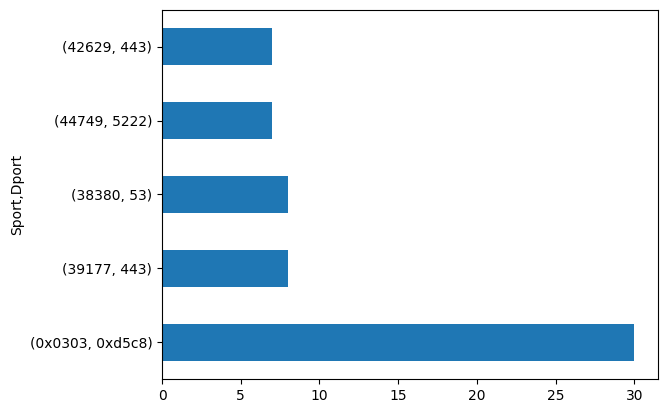

In [29]:
# I see that there are some ports that are inaproprietly written
df[df['traffic_type']=='From-Normal'][['Sport','Dport']].value_counts().sort_values(ascending=False).head(5).plot(kind='barh')

<Axes: ylabel='Sport,Dport'>

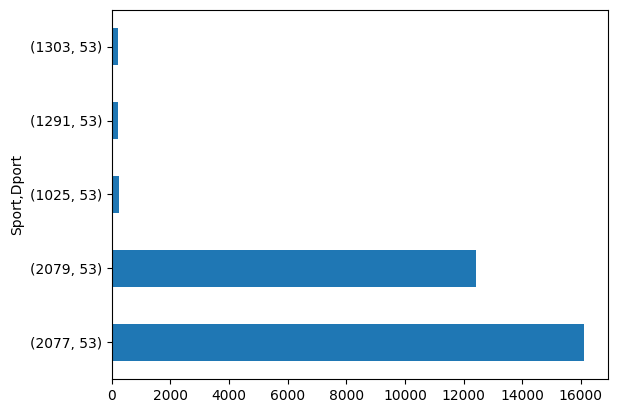

In [30]:
# From this table I see that botnet traffic communication usually comes from unstandardized ports
df[df['traffic_type']=='From-Botnet'][['Sport','Dport']].value_counts().sort_values(ascending=False).head(5).plot(kind='barh')

This is an important finding, in my opinion. I see from this that source port for botnet traffic comes from non-standardized ports and mainly communicates with port 53. Majority of traffic for botnet comes from ports 2077 and 2079! This is a big clue!

Because of some innacurate ports, I will remove Sport and Dport for modelling for now.

In [31]:
df['StartTime'] = pd.to_datetime(df['StartTime'])

In [32]:
print(df['StartTime'].min())
print(df['StartTime'].max())

2011-08-10 09:46:53.160043
2011-08-10 15:54:07.198435


In [33]:
df['StartTime'].dt.floor('h')

,StartTime
0,2011-08-10 09:00:00
1,2011-08-10 09:00:00
2,2011-08-10 09:00:00
3,2011-08-10 09:00:00
4,2011-08-10 09:00:00
...,...
71214,2011-08-10 15:00:00
71215,2011-08-10 15:00:00
71216,2011-08-10 15:00:00
71217,2011-08-10 15:00:00


In [34]:
hourly_traffic = pd.crosstab(
    df['StartTime'].dt.floor('h'),
    df['traffic_type']
)

display(hourly_traffic)

traffic_type,From-Botnet,From-Normal
StartTime,,
2011-08-10 09:00:00,0,1696
2011-08-10 10:00:00,0,3346
2011-08-10 11:00:00,2825,3868
2011-08-10 12:00:00,5165,6974
2011-08-10 13:00:00,20995,6424
2011-08-10 14:00:00,2526,4141
2011-08-10 15:00:00,9450,3809


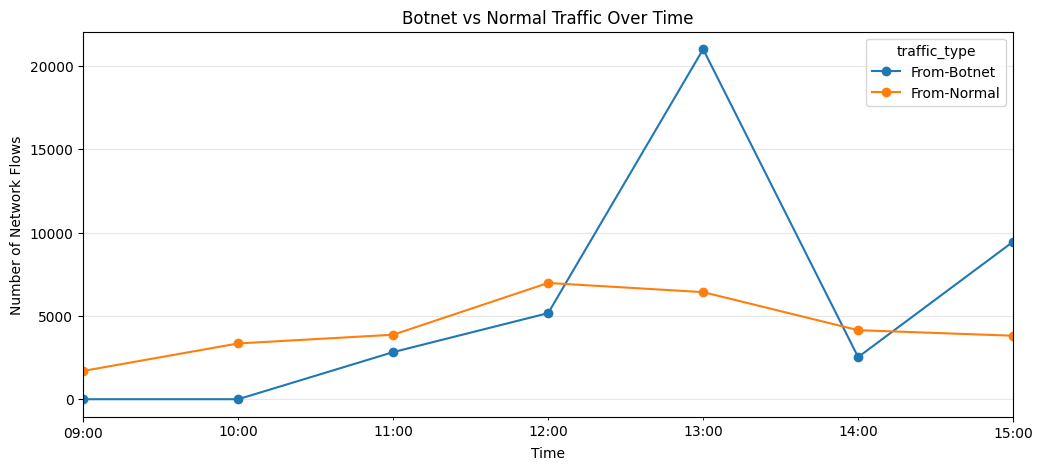

In [35]:
# There is not a certain trend that we can observe,
# I see that botnet traffic begins at 1000 and spikes at 1300, lowers at 1400
# but reappears eventually
import matplotlib.pyplot as plt

hourly_traffic.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Botnet vs Normal Traffic Over Time')
plt.xlabel('Time')
plt.ylabel('Number of Network Flows')
plt.grid(alpha=0.3)
plt.show()

Based on this graph, I will split data for training in following order:
- Training: before 1400
- Validation: 1400-1500
- Test: after 1500

# Modelling info

For modelling I intend to use all of the columns with the exception of the following:
- ***StartTime*** - I don't think it brings any value to the table
- ***SrcAddr*** adn ***DstAddr*** - because there is only one IP address that is a botnet in this dataset, this would technically be leakage

For X, I will use everything but the ***traffic_type***, ***Label*** and ***target***. ***Target*** will be Y

In [36]:
train_df = df[
    df['StartTime'] < '2011-08-10 14:00:00'
].copy()

val_df = df[
    (df['StartTime'] >= '2011-08-10 14:00:00') &
    (df['StartTime'] < '2011-08-10 15:00:00')
].copy()

test_df = df[
    df['StartTime'] >= '2011-08-10 15:00:00'
].copy()

In [37]:
train_df['target'].value_counts()

,count
target,
1,28985
0,22308


In [38]:
val_df['target'].value_counts()

,count
target,
0,4141
1,2526


In [39]:
test_df['target'].value_counts()

,count
target,
1,9450
0,3809


In [40]:
drop_cols = ['StartTime', 'SrcAddr', 'DstAddr', 'Sport', 'Dport', 'Label', 'traffic_type', 'target']

X_train = train_df.drop(columns=drop_cols)
y_train = train_df['target']

X_val = val_df.drop(columns=drop_cols)
y_val = val_df['target']

X_test = test_df.drop(columns=drop_cols)
y_test = test_df['target']

In [41]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(51293, 9)
(6667, 9)
(13259, 9)


In [42]:
X_train.dtypes

,0
Dur,float64
Proto,object
Dir,object
State,object
sTos,float64
dTos,float64
TotPkts,int64
TotBytes,int64
SrcBytes,int64


In [43]:
numeric_cols = ['Dur', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes']
categorical_cols = ['Proto', 'Dir', 'State']

In [44]:
X_train.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,10
dTos,8336
TotPkts,0
TotBytes,0
SrcBytes,0


In [45]:
X_val.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,2
dTos,2256
TotPkts,0
TotBytes,0
SrcBytes,0


In [46]:
X_test.isna().sum()

,0
Dur,0
Proto,0
Dir,0
State,0
sTos,1
dTos,2416
TotPkts,0
TotBytes,0
SrcBytes,0


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [49]:
numeric_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median',add_indicator=True)),
        ('scaler', StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ]
)

In [51]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Dur', 'sTos', 'dTos', 'TotPkts', 'TotBytes',
                                  'SrcBytes']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Proto', 'Dir', 'State'])])


# **Logistic Regression**

In [52]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [53]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Dur', 'sTos', 'dTos',
                                                   'TotPkts', 'TotBytes',
                                                   'SrcBytes']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Proto', 'Dir', 'State'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [55]:
y_pred_lr = lr_pipeline.predict(X_val)

In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score
)

print(f'Accuracy: {accuracy_score(y_val, y_pred_lr)}')
print(f'Precision: {precision_score(y_val, y_pred_lr)}')
print(f'Recall Score: {recall_score(y_val, y_pred_lr)}')

Accuracy: 0.5611219439028049
Precision: 0.4613601236476043
Recall Score: 0.9453681710213777


In [61]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_lr,
    target_names=['Normal', 'Botnet'],
    digits=4
))

              precision    recall  f1-score   support

      Normal     0.9074    0.3267    0.4805      4141
      Botnet     0.4614    0.9454    0.6201      2526

    accuracy                         0.5611      6667
   macro avg     0.6844    0.6361    0.5503      6667
weighted avg     0.7384    0.5611    0.5334      6667



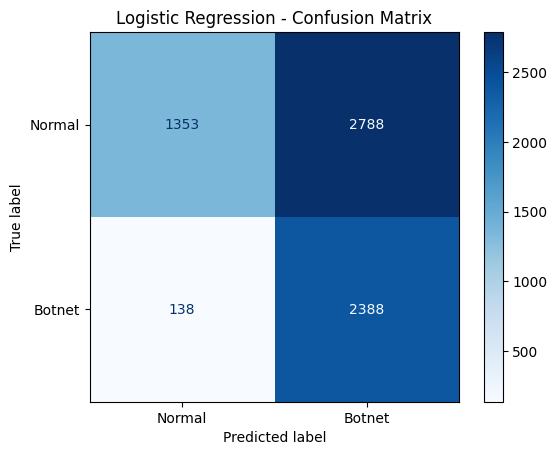

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lr,
    display_labels=['Normal', 'Botnet'],
    cmap='Blues',
    values_format='d'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [64]:
print("Train Accuracy:",
      lr_pipeline.score(X_train, y_train))

print("Validation Accuracy:",
      lr_pipeline.score(X_val, y_val))

Train Accuracy: 0.6806386836410426
Validation Accuracy: 0.5611219439028049
